# 概要 overview

予測モデルのハイパーパラメータチューニング
Optunaを用いて探索を行う。
交差検証を行い、

作成するモデルは下記
 1. 勾配ブースティング決定木（GBDT）
 2. RandomForest
 3. ニューラルネットワーク（NN）

## ライブラリ読み込み

In [5]:
import torch

# 自作関数 "src"参照
from src.Data_load_And_Preprocess import data_load_and_preprocess
from src.GBDT_param_tuning import Optimize_lightGBM
from src.RndomForest_param_tuning import Optimize_RandomForest
from src.NN_param_tuning import Optimize_NN

## データの読み込み

データの読み込みおよび訓練データ・テストデータの分割
テストデータは最後の精度比較に使用

In [6]:
X_train, X_test, Y_train, Y_test = data_load_and_preprocess()

Number of samples: 1030
Number of features: 8


## GBDTモデルのハイパーパラメータ探索

trainデータに対して交差検証による探索を行う。
探索結果は"./results/GBDT/trials_history.csv"に保存


[I 2026-11-27 18:17:48,267] A new study created in memory with name: subrutin_lgbm_tuning


[I 2026-11-27 18:17:51,879] Trial 0 finished with value: 10.210457371241864 and parameters: {'learning_rate': 0.001, 'num_leaves': 86, 'max_depth': 7, 'min_child_samples': 46, 'subsample': 0.9199999999999999, 'colsample_bytree': 0.95, 'reg_alpha': 0.0, 'reg_lambda': 0.01}. Best is trial 0 with value: 10.210457371241864.


Trial 1 CV Mean [Avg Best Iter: 1000.0] Train RMSE: 9.7730 | Valid RMSE: 10.2105 | 


[I 2026-11-27 18:17:53,401] Trial 1 finished with value: 5.771706999103176 and parameters: {'learning_rate': 0.01, 'num_leaves': 44, 'max_depth': 5, 'min_child_samples': 50, 'subsample': 0.63, 'colsample_bytree': 0.87, 'reg_alpha': 0.01, 'reg_lambda': 0.0}. Best is trial 1 with value: 5.771706999103176.


Trial 2 CV Mean [Avg Best Iter: 878.8] Train RMSE: 4.8907 | Valid RMSE: 5.7717 | 


[I 2026-11-27 18:17:57,206] Trial 2 finished with value: 6.189496116191283 and parameters: {'learning_rate': 0.01, 'num_leaves': 122, 'max_depth': 3, 'min_child_samples': 72, 'subsample': 0.79, 'colsample_bytree': 0.77, 'reg_alpha': 10.0, 'reg_lambda': 1.0}. Best is trial 1 with value: 5.771706999103176.


... (587 outputs left out)

Trial 299 CV Mean [Avg Best Iter: 122.0] Train RMSE: 2.1596 | Valid RMSE: 4.7322 | 


[I 2026-11-27 18:26:01,873] Trial 299 finished with value: 4.927503979889417 and parameters: {'learning_rate': 0.1, 'num_leaves': 81, 'max_depth': 10, 'min_child_samples': 12, 'subsample': 0.97, 'colsample_bytree': 0.98, 'reg_alpha': 0.1, 'reg_lambda': 0.01}. Best is trial 204 with value: 4.595124948204408.


Trial 300 CV Mean [Avg Best Iter: 97.4] Train RMSE: 1.7943 | Valid RMSE: 4.9275 | 

ハイパーパラメータチューニング完了！
ベストTrial番号: 204
ベストイテレーション（平均）: 135.2 ラウンド
ベスト検証 RMSE: 4.5951
ベスト訓練 RMSE: 1.8065
ベストパラメータ:
  - learning_rate: 0.1
  - num_leaves: 67
  - max_depth: 10
  - min_child_samples: 14
  - subsample: 0.97
  - colsample_bytree: 0.6799999999999999
  - reg_alpha: 0.1
  - reg_lambda: 0.01


c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\GBDT_param_tuning.py:148: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_optimization_history(study)


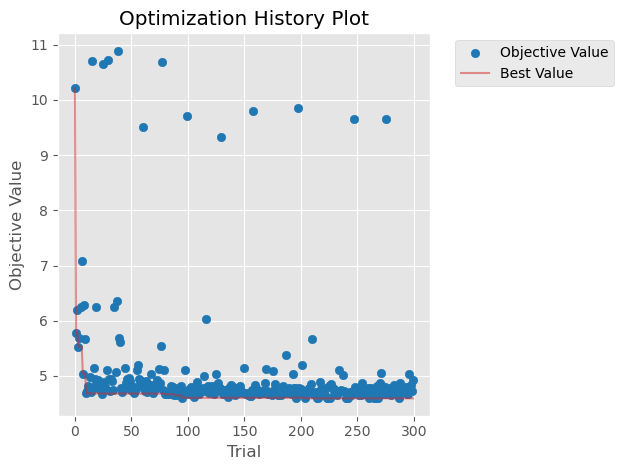

c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\GBDT_param_tuning.py:152: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_param_importances(study)


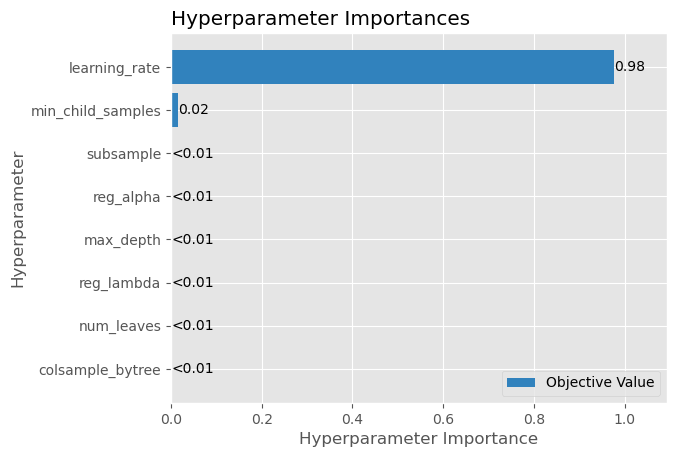

処理時間: 498.08秒


In [7]:
trial_n =300 #Optuna探索試行回数

Optimize_lightGBM(trial_n, X_train, Y_train)

## RndomForestモデルのハイパーパラメータ探索

trainデータに対して交差検証による探索を行う。
探索結果は"./results/RandomForest/trials_history.csv"に保存


[I 2026-11-27 18:26:06,376] A new study created in memory with name: subrutin_lgbm_tuning


[I 2026-11-27 18:26:11,548] Trial 0 finished with value: 8.016446103758312 and parameters: {'max_features': 0.3952423171198838, 'max_depth': 10, 'min_samples_leaf': 15, 'min_samples_split': 15}. Best is trial 0 with value: 8.016446103758312.


Trial 1  Train RMSE: 7.1175 | Valid RMSE: 8.0164 | 


[I 2026-11-27 18:26:16,049] Trial 1 finished with value: 10.550719696541416 and parameters: {'max_features': 0.11427875843269916, 'max_depth': 11, 'min_samples_leaf': 15, 'min_samples_split': 7}. Best is trial 0 with value: 8.016446103758312.


Trial 2  Train RMSE: 9.8136 | Valid RMSE: 10.5507 | 


[I 2026-11-27 18:26:20,181] Trial 2 finished with value: 10.984023071044673 and parameters: {'max_features': 0.16016014152611788, 'max_depth': 9, 'min_samples_leaf': 19, 'min_samples_split': 18}. Best is trial 0 with value: 8.016446103758312.


... (592 outputs left out)

Trial 299  Train RMSE: 2.7282 | Valid RMSE: 5.4196 | 


[I 2026-11-27 18:57:36,066] Trial 299 finished with value: 5.267272030467057 and parameters: {'max_features': 0.9394324404242628, 'max_depth': 23, 'min_samples_leaf': 1, 'min_samples_split': 3}. Best is trial 197 with value: 5.25184435230564.


Trial 300  Train RMSE: 2.1491 | Valid RMSE: 5.2673 | 

ハイパーパラメータチューニング完了！
ベストTrial番号: 197
ベスト検証 RMSE: 5.2518
ベスト訓練 RMSE: 2.0532
ベストパラメータ:
  - max_features: 0.874156222444719
  - max_depth: 12
  - min_samples_leaf: 1
  - min_samples_split: 2


c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\RndomForest_param_tuning.py:140: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_optimization_history(study)


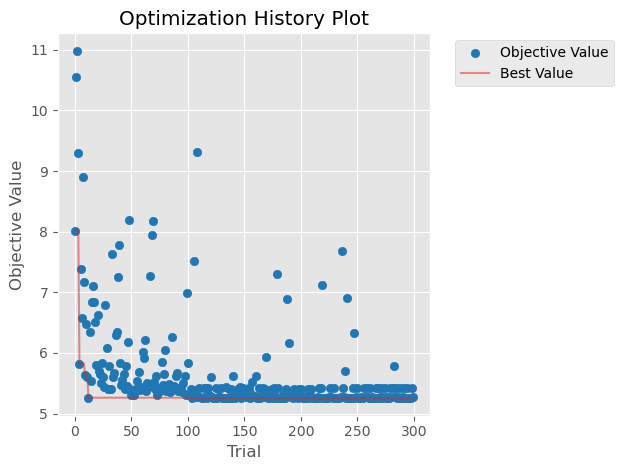

c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\RndomForest_param_tuning.py:144: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_param_importances(study)


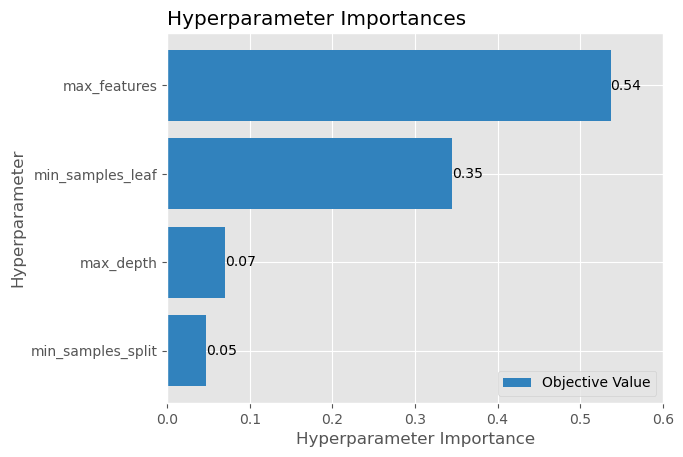

処理時間: 1894.63秒


In [8]:
trial_n =300 #Optuna探索試行回数

Optimize_RandomForest(trial_n, X_train, Y_train)

## ニューラルネットワークモデルのハイパーパラメータ探索

trainデータに対して交差検証による探索を行う。
探索結果は"./results/NN/trials_history.csv"に保存

[I 2026-11-27 18:57:41,040] A new study created in memory with name: subrutin_lgbm_tuning


Device: cpu


[I 2026-11-27 18:58:10,688] Trial 0 finished with value: 6.601873991822499 and parameters: {'n_layers': 2, 'hidden_dim_0': 224, 'hidden_dim_1': 224, 'dropout_rate': 0.5, 'learning_rate': 0.001}. Best is trial 0 with value: 6.601873991822499.


Trial 1 CV Mean [Avg Best Iter: 29.2] Train RMSE: 5.8939 | Valid RMSE: 6.6019 | 


[I 2026-11-27 18:59:14,320] Trial 1 finished with value: 6.827276642746999 and parameters: {'n_layers': 1, 'hidden_dim_0': 48, 'dropout_rate': 0.4, 'learning_rate': 0.0005}. Best is trial 0 with value: 6.601873991822499.


Trial 2 CV Mean [Avg Best Iter: 154.0] Train RMSE: 6.4384 | Valid RMSE: 6.8273 | 


... (593 outputs left out)

Trial 299 CV Mean [Avg Best Iter: 19.0] Train RMSE: 3.6608 | Valid RMSE: 5.3725 | 


[I 2026-11-27 20:43:15,627] Trial 299 finished with value: 5.294586010618654 and parameters: {'n_layers': 3, 'hidden_dim_0': 224, 'hidden_dim_1': 208, 'hidden_dim_2': 112, 'dropout_rate': 0.0, 'learning_rate': 0.001}. Best is trial 103 with value: 5.044491104098069.


Trial 300 CV Mean [Avg Best Iter: 20.0] Train RMSE: 3.5863 | Valid RMSE: 5.2946 | 

ハイパーパラメータチューニング完了！
ベストTrial番号: 103
ベストイテレーション（平均）: 26.4 ラウンド
ベスト検証 RMSE: 5.0445
ベスト訓練 RMSE: 3.2768
ベストパラメータ:
  - n_layers: 3
  - hidden_dim_0: 224
  - hidden_dim_1: 208
  - hidden_dim_2: 128
  - dropout_rate: 0.0
  - learning_rate: 0.001


c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\NN_param_tuning.py:181: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_optimization_history(study)


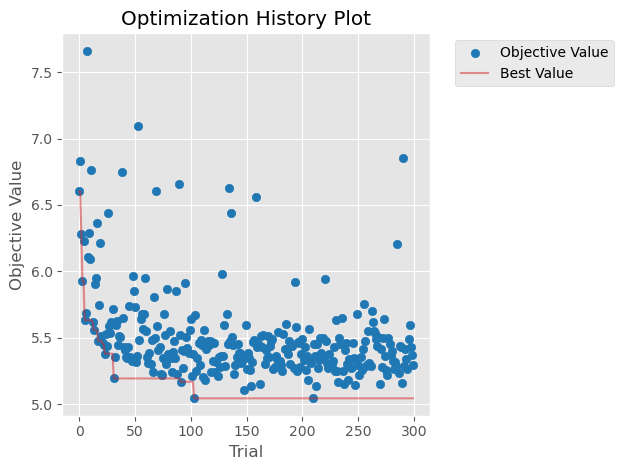

c:\Users\tapap\Desktop\コード置き場\Project01_ConcreteStrength_Regression\src\NN_param_tuning.py:185: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  vis_plt.plot_param_importances(study)


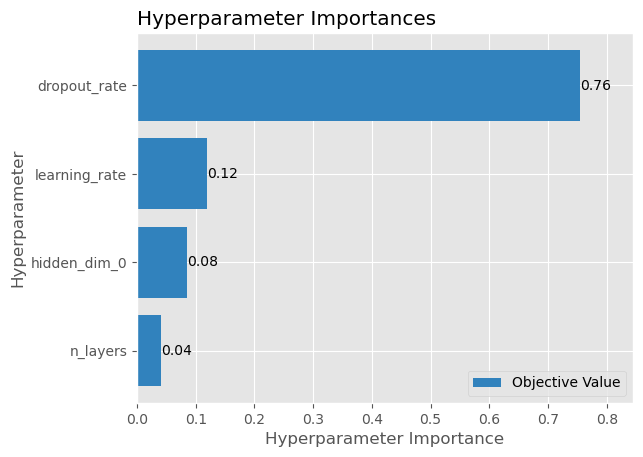

処理時間: 6337.13秒


In [9]:
# Device selection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

trial_n =300 #Optuna探索試行回数

Optimize_NN(trial_n, X_train, Y_train, device)